In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw, MolFromSmiles, MolToSmiles

# Preprocess

In [2]:
df = pd.read_table(r'D:\workspace\pycharm\smiles-transformer\tests\data\chembl\chembl_24_chemreps.txt')
L = len(df)
print(L)
df.head()

1820035


,chembl_id,canonical_smiles,standard_inchi,standard_inchi_key
0,CHEMBL153534,Cc1cc(cn1C)c2csc(N=C(N)N)n2,InChI=1S/C10H13N5S/c1-6-3-7(4-15(6)2)8-5-16-10...,MFRNFCWYPYSFQQ-UHFFFAOYSA-N
1,CHEMBL440060,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@@H...,InChI=1S/C123H212N44O34S/c1-19-63(12)96(164-11...,RSEQNZQKBMRQNM-VRGFNVLHSA-N
2,CHEMBL440245,CCCC[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CCCCN...,InChI=1S/C160H268N50O41/c1-23-27-41-95-134(228...,FTKBTEIKPOYCEX-OZSLQWTKSA-N
3,CHEMBL440249,CC(C)C[C@@H]1NC(=O)CNC(=O)[C@@H](NC(=O)[C@H](N...,InChI=1S/C124H154ClN21O39/c1-57(2)48-81-112(17...,UYSXXKGACMHPIM-KFGDMSGDSA-N
4,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN4CCOCC4,InChI=1S/C19H21BrN6O/c20-15-2-1-3-17(18(15)22-...,VDSXZXJEWIWBCG-UHFFFAOYSA-N


In [3]:
x = df['canonical_smiles'].values
y =[]
for i in range(5):
    y.append(x[i].split())
print(y)

[['Cc1cc(cn1C)c2csc(N=C(N)N)n2'], ['CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@@H](NC(=O)[C@@H](N)CCSC)[C@@H](C)O)C(=O)NCC(=O)N[C@@H](C)C(=O)N[C@@H](C)C(=O)N[C@@H](Cc1c[nH]cn1)C(=O)N[C@@H](CC(=O)N)C(=O)NCC(=O)N[C@@H](C)C(=O)N[C@@H](C)C(=O)N[C@@H](CCC(=O)N)C(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](CCCN=C(N)N)C(=O)N[C@@H](CCC(=O)N)C(=O)N[C@@H](CC(C)C)C(=O)N[C@@H](CCCN=C(N)N)C(=O)NCC(=O)N[C@@H](CCC(=O)N)C(=O)N[C@@H](CC(C)C)C(=O)NCC(=O)N2CCC[C@H]2C(=O)N3CCC[C@H]3C(=O)NCC(=O)N[C@@H](CO)C(=O)N[C@@H](CCCN=C(N)N)C(=O)N'], ['CCCC[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CCCCN)NC(=O)[C@H](CCCN=C(N)N)NC(=O)[C@H](CC(=O)N)NC(=O)[C@H](CO)NC(=O)[C@H](Cc1c[nH]cn1)NC(=O)[C@H](C)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](C)NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@@H]2CCCCNC(=O)CC[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@@H](NC(=O)[C@H](CCC(=O)O)NC(=O)[C@H](CCCN=C(N)N)NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC(C)C)NC(=O)[C@H](Cc3c[nH]cn3)NC(=O)[C@H](N)Cc4ccccc4)C(C)C)C(=O)N[C@@H](CCCC)C(=O)N[C@@

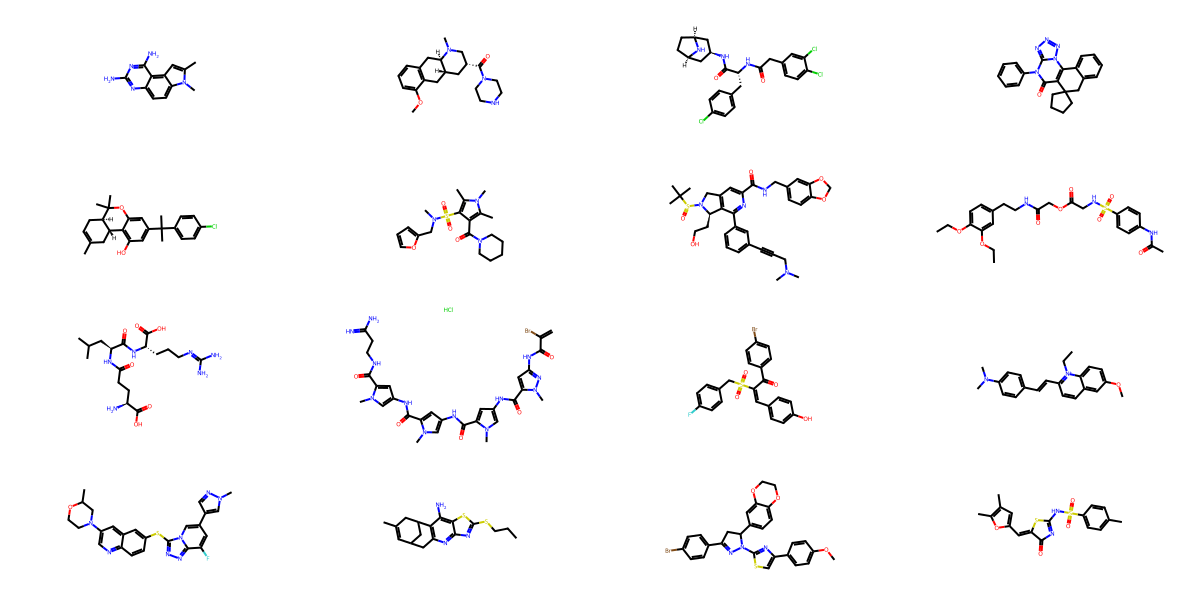

In [9]:
rands = np.random.choice(L, 16, replace=False)
smiles = df.iloc[rands]['canonical_smiles'].values
mols = []
for s in smiles:
    if s is None:
        continue
    mol = MolFromSmiles(s)
    if mol is not None:
        mols.append(mol)
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300,150))

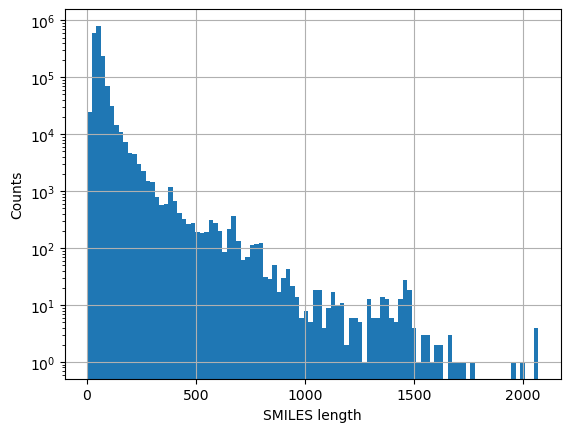

In [10]:
lengths = list(map(len, df['canonical_smiles'].values))

plt.hist(lengths, bins=100)
plt.grid()
plt.xlabel('SMILES length')
plt.ylabel('Counts')
plt.yscale('log')

Text(0, 0.5, 'Counts')

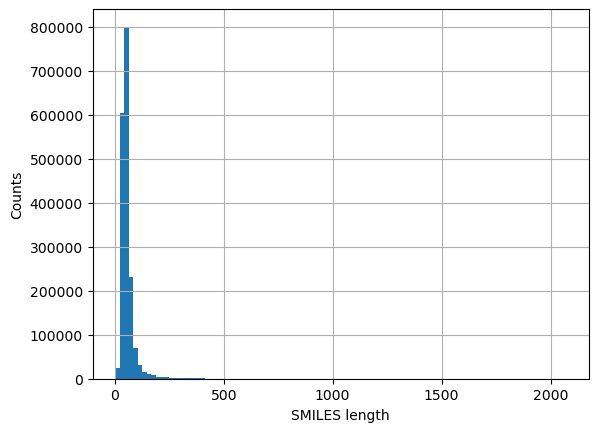

In [11]:
plt.hist(lengths, bins=100)
plt.grid()
plt.xlabel('SMILES length')
plt.ylabel('Counts')

Text(0, 0.5, 'Counts')

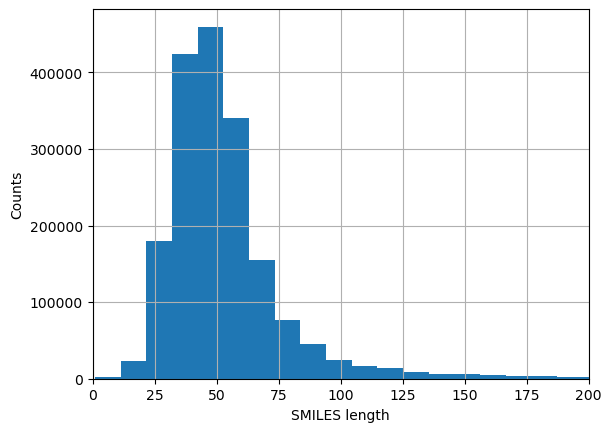

In [12]:
plt.hist(lengths, bins=200)
plt.grid()
plt.xlim([0,200])
plt.xlabel('SMILES length')
plt.ylabel('Counts')

In [13]:
np.sum(np.array(lengths)<=100)/L*100

np.float64(94.62993843524987)

In [14]:
df_sub = df[np.array(lengths)<=100]
print(len(df_sub))

1722298


In [15]:
lengths2 = list(map(len, df_sub['canonical_smiles'].values))
print(np.max(lengths2))

100


In [16]:
df_sub.to_csv('chembl_24_100.csv', index=False)

In [95]:
df = pd.read_table(r'D:\workspace\pycharm\smiles-transformer\tests\data\chembl\chembl_24_chemreps.txt')
L = len(df)
print(L)
df.head()

1820035


,chembl_id,canonical_smiles,standard_inchi,standard_inchi_key
0,CHEMBL153534,Cc1cc(cn1C)c2csc(N=C(N)N)n2,InChI=1S/C10H13N5S/c1-6-3-7(4-15(6)2)8-5-16-10...,MFRNFCWYPYSFQQ-UHFFFAOYSA-N
1,CHEMBL440060,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@@H...,InChI=1S/C123H212N44O34S/c1-19-63(12)96(164-11...,RSEQNZQKBMRQNM-VRGFNVLHSA-N
2,CHEMBL440245,CCCC[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CCCCN...,InChI=1S/C160H268N50O41/c1-23-27-41-95-134(228...,FTKBTEIKPOYCEX-OZSLQWTKSA-N
3,CHEMBL440249,CC(C)C[C@@H]1NC(=O)CNC(=O)[C@@H](NC(=O)[C@H](N...,InChI=1S/C124H154ClN21O39/c1-57(2)48-81-112(17...,UYSXXKGACMHPIM-KFGDMSGDSA-N
4,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN4CCOCC4,InChI=1S/C19H21BrN6O/c20-15-2-1-3-17(18(15)22-...,VDSXZXJEWIWBCG-UHFFFAOYSA-N


In [17]:
smiles  = df['canonical_smiles'].values
to_drop = []
for i,sm in enumerate(smiles):
    if len(sm)>100:
        to_drop.append(i)
    if df['chembl_id'][i]=='CHEMBL1201364':
        to_drop.append(i)
print(len(to_drop))

97738


In [18]:
df_dropped = df.drop(to_drop)
df_dropped = df_dropped.drop(['standard_inchi', 'standard_inchi_key'], axis=1)
L = len(df_dropped)
print(L)
df_dropped.head()

1722297


,chembl_id,canonical_smiles
0,CHEMBL153534,Cc1cc(cn1C)c2csc(N=C(N)N)n2
4,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN4CCOCC4
5,CHEMBL503634,COc1c(O)cc(O)c(C(=N)Cc2ccc(O)cc2)c1O
6,CHEMBL503643,CCOC(=O)c1cc2cc(ccc2[nH]1)C(=O)O
8,CHEMBL503870,C[C@H](NC(=O)OCc1ccccc1)C(=O)N[C@@H](C)C(=O)NN...


In [19]:
df_dropped.to_csv('D:\\workspace\\pycharm\\smiles-transformer\\experiments\\chembl_24_100.csv', index=False)

In [20]:
smiles = df['canonical_smiles'].values

# words = ['Cl', 'Br', 'At', 'Se', 'As', 'Si', 'Be', 'Ca', 'Mg', 'Li', 'Na', 'P+', 'O-', 'S-', 'Se-', 'N+', 'As+', 'Na+', 'Li+', 'H+',\
#         'K+', 'F-', 'Cl-', 'Br-', 'I-']
# for w in words:
#     cnt = 0
#     for smile in smiles:
#         if w in smile:
#             if cnt<5:
#                 print(smile)
#             cnt += 1
#     print(w, cnt/L*100, '\n')

In [21]:
smiles = df['canonical_smiles'].values
pro_sms = []
for sm in smiles:
    sm = ' '.join(list(sm))
    before = ['C l -', 'C l', 'O -', 'N +', 'n +', 'B r -', 'B r', 'N a +', 'N a', 'I -', 'S i']
    after = ['Cl-', 'Cl', 'O-', 'N+', 'n+', 'Br-', 'Br', 'Na+', 'Na', 'I-', 'Si']
    for b,a in zip(before, after):
        sm = sm.replace(b, a)
    pro_sms.append(sm)

In [22]:
df['processed_smiles'] = pro_sms
df.head()

,chembl_id,canonical_smiles,standard_inchi,standard_inchi_key,processed_smiles
0,CHEMBL153534,Cc1cc(cn1C)c2csc(N=C(N)N)n2,InChI=1S/C10H13N5S/c1-6-3-7(4-15(6)2)8-5-16-10...,MFRNFCWYPYSFQQ-UHFFFAOYSA-N,C c 1 c c ( c n 1 C ) c 2 c s c ( N = C ( N ) ...
1,CHEMBL440060,CC[C@H](C)[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@@H...,InChI=1S/C123H212N44O34S/c1-19-63(12)96(164-11...,RSEQNZQKBMRQNM-VRGFNVLHSA-N,C C [ C @ H ] ( C ) [ C @ H ] ( N C ( = O ) [ ...
2,CHEMBL440245,CCCC[C@H](NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CCCCN...,InChI=1S/C160H268N50O41/c1-23-27-41-95-134(228...,FTKBTEIKPOYCEX-OZSLQWTKSA-N,C C C C [ C @ H ] ( N C ( = O ) [ C @ H ] ( C ...
3,CHEMBL440249,CC(C)C[C@@H]1NC(=O)CNC(=O)[C@@H](NC(=O)[C@H](N...,InChI=1S/C124H154ClN21O39/c1-57(2)48-81-112(17...,UYSXXKGACMHPIM-KFGDMSGDSA-N,C C ( C ) C [ C @ @ H ] 1 N C ( = O ) C N C ( ...
4,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN4CCOCC4,InChI=1S/C19H21BrN6O/c20-15-2-1-3-17(18(15)22-...,VDSXZXJEWIWBCG-UHFFFAOYSA-N,Br c 1 c c c c ( N c 2 n c n c 3 c c n c c 2 3...


In [23]:
to_drop = []
for i,sm in enumerate(smiles):
    if len(sm)>100:
        to_drop.append(i)
print(len(to_drop))

97737


In [24]:
df_dropped = df.drop(to_drop)
df_dropped = df_dropped.drop(['standard_inchi', 'standard_inchi_key'], axis=1)
L = len(df_dropped)
print(L)
df_dropped.head()

1722298


,chembl_id,canonical_smiles,processed_smiles
0,CHEMBL153534,Cc1cc(cn1C)c2csc(N=C(N)N)n2,C c 1 c c ( c n 1 C ) c 2 c s c ( N = C ( N ) ...
4,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN4CCOCC4,Br c 1 c c c c ( N c 2 n c n c 3 c c n c c 2 3...
5,CHEMBL503634,COc1c(O)cc(O)c(C(=N)Cc2ccc(O)cc2)c1O,C O c 1 c ( O ) c c ( O ) c ( C ( = N ) C c 2 ...
6,CHEMBL503643,CCOC(=O)c1cc2cc(ccc2[nH]1)C(=O)O,C C O C ( = O ) c 1 c c 2 c c ( c c c 2 [ n H ...
8,CHEMBL503870,C[C@H](NC(=O)OCc1ccccc1)C(=O)N[C@@H](C)C(=O)NN...,C [ C @ H ] ( N C ( = O ) O C c 1 c c c c c 1 ...


In [25]:
df_dropped.to_csv('D:\workspace\pycharm\smiles-transformer\experiments\chembl_24_100.csv')

In [105]:
smiles = df_dropped['processed_smiles'].values
rands = np.random.choice(L, L, replace=False)
test_size = 10000
with open('D:\\workspace\\pycharm\\smiles-transformer\\tests\\data\\chembl\\sentence_test.txt', 'a') as f:
    for i in range(0, test_size):
        f.write(smiles[rands[i]]+'\n')
        
with open('D:\\workspace\\pycharm\\smiles-transformer\\tests\\data\\chembl\\sentence_train.txt', 'a') as f:
    for i in range(test_size, L):
        f.write(smiles[rands[i]]+'\n')

# Create vocabulary

In [107]:
smiles = df_dropped['processed_smiles'].values
vocab = []
for sm in smiles:
    l = sm.split(' ')
    for w in l:
        if w not in vocab:
            vocab.append(w)

with open('D:\\workspace\\pycharm\\smiles-transformer\\tests\\data\\chembl\\vocab.txt', 'a') as f:
    for v in vocab:
        f.write(v+'\n')

# Solubility dataset

In [26]:
df_sol = pd.read_csv(r'D:\workspace\pycharm\smiles-transformer\data\model_v2_datasets\data_198\data.csv')
df_sol.head()

,number,smiles,lam_abs,lam_em,eps
0,1,C1=CC=C(C=C1)C2=C3N=C4C(=CC(=[N+]4[B-](F)(F)N3...,640,688.0,79000.0
1,2,CCN(CC)C1=CC=C(C=C1)C2=CC(=[N+]3C2=NC4=C(C=C(C...,799,960.0,40000.0
2,3,COC1=CC=C(C=C1)C2=C(C=O)C(=C(/N=C\3/C(=C(C=O)C...,1020,NaN,NaN
3,5,CCN(CC)C1=CC=C(C=C1)C2=CC(=C3N=C4C(=CC(=[N+]4[...,859,998.0,NaN
4,6,CCN(CC)C1=CC=C(C=C1)C2=CC(=C(N=C3C(=CC(=N3)C4=...,880,980.0,NaN


In [27]:
smiles = df_sol['smiles'].values
pro_sms = []
for sm in smiles:
    sm = ' '.join(list(sm))
    before = ['C l -', 'C l', 'O -', 'N +', 'n +', 'B r -', 'B r', 'N a +', 'N a', 'I -', 'S i']
    after = ['Cl-', 'Cl', 'O-', 'N+', 'n+', 'Br-', 'Br', 'Na+', 'Na', 'I-', 'Si']
    for b,a in zip(before, after):
        sm = sm.replace(b, a)
    pro_sms.append(sm)

df_sol['processed_smiles'] = pro_sms
df_sol.head()

,number,smiles,lam_abs,lam_em,eps,processed_smiles
0,1,C1=CC=C(C=C1)C2=C3N=C4C(=CC(=[N+]4[B-](F)(F)N3...,640,688.0,79000.0,C 1 = C C = C ( C = C 1 ) C 2 = C 3 N = C 4 C ...
1,2,CCN(CC)C1=CC=C(C=C1)C2=CC(=[N+]3C2=NC4=C(C=C(C...,799,960.0,40000.0,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...
2,3,COC1=CC=C(C=C1)C2=C(C=O)C(=C(/N=C\3/C(=C(C=O)C...,1020,NaN,NaN,C O C 1 = C C = C ( C = C 1 ) C 2 = C ( C = O ...
3,5,CCN(CC)C1=CC=C(C=C1)C2=CC(=C3N=C4C(=CC(=[N+]4[...,859,998.0,NaN,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...
4,6,CCN(CC)C1=CC=C(C=C1)C2=CC(=C(N=C3C(=CC(=N3)C4=...,880,980.0,NaN,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...


In [28]:
df_sol.to_csv(r'D:\workspace\pycharm\smiles-transformer\data\model_v2_datasets\data_198\data.csv')

In [29]:
df_sol = pd.read_csv(r'D:\workspace\pycharm\smiles-transformer\data\model_v2_datasets\data_198\data.csv')
df_sol.head()

,Unnamed: 0,number,smiles,lam_abs,lam_em,eps,processed_smiles
0,0,1,C1=CC=C(C=C1)C2=C3N=C4C(=CC(=[N+]4[B-](F)(F)N3...,640,688.0,79000.0,C 1 = C C = C ( C = C 1 ) C 2 = C 3 N = C 4 C ...
1,1,2,CCN(CC)C1=CC=C(C=C1)C2=CC(=[N+]3C2=NC4=C(C=C(C...,799,960.0,40000.0,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...
2,2,3,COC1=CC=C(C=C1)C2=C(C=O)C(=C(/N=C\3/C(=C(C=O)C...,1020,NaN,NaN,C O C 1 = C C = C ( C = C 1 ) C 2 = C ( C = O ...
3,3,5,CCN(CC)C1=CC=C(C=C1)C2=CC(=C3N=C4C(=CC(=[N+]4[...,859,998.0,NaN,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...
4,4,6,CCN(CC)C1=CC=C(C=C1)C2=CC(=C(N=C3C(=CC(=N3)C4=...,880,980.0,NaN,C C N ( C C ) C 1 = C C = C ( C = C 1 ) C 2 = ...


In [30]:
N = len(df_sol)
test_size = int(N*0.15)
rands = np.random.choice(N,N, replace=False)
df_test = df_sol.iloc[rands[:test_size]]
print("Test size", len(df_test))
df_train = df_sol.iloc[rands[test_size:]]
print("Train size", len(df_train))

Test size 26
Train size 151


In [31]:
df_train.to_csv(r'D:\workspace\pycharm\smiles-transformer\data\model_v2_datasets\data_198\data_with_processed\data_train.csv')
df_test.to_csv(r'D:\workspace\pycharm\smiles-transformer\data\model_v2_datasets\data_198\data_with_processed\data_test.csv')